In [1]:
import pandas as pd
import polars as pl
import svy
import numpy as np
import matplotlib.pyplot as plt

In [2]:
h3_df = pd.read_csv('../data/processed/h3_analytic_sample.csv')
# Drops the one record flagged as a laboratory/recording error in
# pipeline/nhanes_helpers.py (implausible_free_t3).
h3_df = h3_df[~h3_df['ft3_implausible']]
h3_pooled = h3_df.assign(wt_pooled = h3_df['wt_thyroid_2yr'] / 2)

design = svy.Design(
    stratum='SDMVSTRA',
    psu='SDMVPSU',
    wgt='wt_pooled'
)
h3_pl = pl.from_pandas(h3_pooled)
sample = svy.Sample(h3_pl, design=design)

# Sensitivity check: untransformed CRP, less trustworthy given the skew below
model_h3_raw = svy.GLM(sample)
model_h3_raw.fit(
    y='LBXCRP',
    x=['LBXT3F', 'RIDAGEYR', svy.Cat('RIAGENDR', ref=1), 'BMXBMI'],
    family='gaussian',
)
print(model_h3_raw)

GLM: Gaussian (identity)
  Modeling : LBXCRP
  n            : 6270          DF Residuals : 28
  Deviance     : 2888.3352     Scale        : 91.4553
  AIC          : 12947.8717    BIC          : -
  R-squared    : 0.09139       R-sq (adj)   : 0.09081
  F-stat (adj) : 52.71233      Prob (F-adj) : <0.001

Coefficients:
  Term          Coef.     Std.Err.  t         P>|t|   [0.025    0.975]  
  ------------  --------  --------  --------  ------  --------  --------
  _intercept_   -0.59428  0.10582   -5.61584  <0.001  -0.81105  -0.37751
  LBXT3F        -0.01255  0.02564   -0.48944  0.6283  -0.06508  0.03998 
  RIDAGEYR      0.00121   0.00058   2.07243   0.0475  0.00001   0.00240 
  RIAGENDR_2.0  0.12280   0.01821   6.74314   <0.001  0.08550   0.16011 
  BMXBMI        0.03127   0.00232   13.46769  <0.001  0.02652   0.03603 


C:\Users\CONNOR\AppData\Local\Temp\ipykernel_468\2668456015.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  h3_pooled = h3_df.assign(wt_pooled = h3_df['wt_thyroid_2yr'] / 2)


C:\Users\CONNOR\AppData\Local\Temp\ipykernel_468\154774186.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  h3_pooled['log_crp'] = np.log(h3_pooled['LBXCRP'])


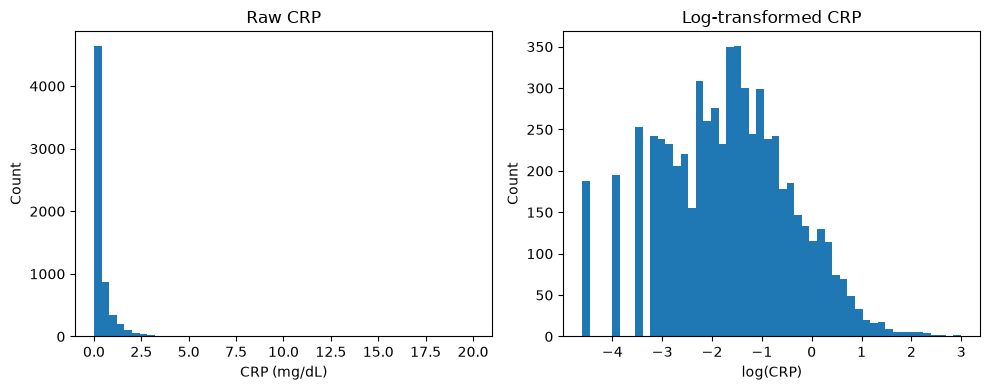

In [3]:
h3_pooled['log_crp'] = np.log(h3_pooled['LBXCRP'])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(h3_pooled['LBXCRP'], bins=50)
axes[0].set_title('Raw CRP')
axes[0].set_xlabel('CRP (mg/dL)')
axes[0].set_ylabel('Count')

axes[1].hist(h3_pooled['log_crp'], bins=50)
axes[1].set_title('Log-transformed CRP')
axes[1].set_xlabel('log(CRP)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [4]:
# Primary model: log-transformed CRP
sample_log = svy.Sample(pl.from_pandas(h3_pooled), design=design)
model_h3_log = svy.GLM(sample_log)
model_h3_log.fit(
    y='log_crp',
    x=['LBXT3F', 'RIDAGEYR', svy.Cat('RIAGENDR', ref=1), 'BMXBMI'],
    family='gaussian',
)
print(model_h3_log)

GLM: Gaussian (identity)
  Modeling : log_crp
  n            : 6270          DF Residuals : 28
  Deviance     : 8024.1308     Scale        : 254.0735
  AIC          : 19362.8519    BIC          : -
  R-squared    : 0.25138       R-sq (adj)   : 0.25091
  F-stat (adj) : 247.19488     Prob (F-adj) : <0.001

Coefficients:
  Term          Coef.     Std.Err.  t          P>|t|   [0.025    0.975]  
  ------------  --------  --------  ---------  ------  --------  --------
  _intercept_   -5.80904  0.26136   -22.22582  <0.001  -6.34442  -5.27366
  LBXT3F        0.22671   0.07005   3.23631    0.0031  0.08321   0.37020 
  RIDAGEYR      0.00968   0.00160   6.06065    <0.001  0.00641   0.01296 
  RIAGENDR_2.0  0.34865   0.04371   7.97697    <0.001  0.25912   0.43818 
  BMXBMI        0.09218   0.00330   27.93392   <0.001  0.08542   0.09894 


/var/folders/rs/yth10b8d4v1043_hxt3sv4x40000gn/T/ipykernel_17317/1602903247.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  h3_pooled['log_crp'] = np.log(h3_pooled['LBXCRP'])
